# Do Socioeconomic Factors Predict ACT Scores?

## Introduction

In this project I look at whether a school's average ACT score can be predicted from socioeconomic factors. I use five socioeconomic measures: the unemployment rate, the percent of adults with a college degree, the percent of children in married-couple families, and the median household income of students, plus the percent of the school's students who qualify for free or reduced-price lunch. As an additional predictor, I also look at whether the school is a charter school, to see if charter schools score differently.

## Data Source

I use two data sets:

- EdGap: The EdGap data come from [EdGap.org](https://www.edgap.org/). Each row is one U.S. school with its average ACT score, the percent of students on free or reduced-price lunch, and socioeconomic measures for the school.
- NCES Common Core of Data (CCD): The school information comes from the National Center for Education Statistics (NCES) public school directory for the 2016–2017 school year: https://nces.ed.gov/ccd/files.asp.

## Importing Libraries

I import every library used in the notebook here:

In [4]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objs as pg
import plotly.offline as po
import seaborn as sns
from scipy import stats
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.stats.anova import anova_lm
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")

The cell runs without output, which means every library is installed and loaded.

## Loading the Data

I load the EdGap data straight from the course GitHub repository. I read the school ID column as text so pandas does not treat it as a number.

In [7]:
edgap = pd.read_excel('https://raw.githubusercontent.com/brian-fischer/DATA-5100/main/EdGap_data.xlsx',dtype={'NCESSCH School ID': object})

/opt/anaconda3/lib/python3.12/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning:

Unknown extension is not supported and will be removed



Next I load the NCES school directory for the 2016–2017 school year from a local CSV file. 

In [9]:
school_information = pd.read_csv(
    "ccd_sch_029_1617_w_1a_11212017.csv",
    encoding="unicode_escape",
    dtype={"NCESSCH": str},
    low_memory=False,
)

The file loads without errors. Each row is one school, and I look at the columns in the next section.

## Inspecting the Data

Before changing anything, I look at the first few rows, the size, and the column types of each data set.

In [12]:
edgap.head()

,NCESSCH School ID,CT Unemployment Rate,CT Pct Adults with College Degree,CT Pct Childre In Married Couple Family,CT Median Household Income,School ACT average (or equivalent if SAT score),School Pct Free and Reduced Lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


Each EdGap row is one school. The columns starting with "CT" describe the census tract around the school: unemployment rate, percent of adults with a college degree, percent of children in married-couple families, and median household income. The last two columns describe the school itself: its average ACT score and the percent of students who qualify for free or reduced-price lunch.

In [14]:
school_information.head()

,SCHOOL_YEAR,FIPST,STATENAME,ST,SCH_NAME,LEA_NAME,STATE_AGENCY_NO,UNION,ST_LEAID,LEAID,...,G_10_OFFERED,G_11_OFFERED,G_12_OFFERED,G_13_OFFERED,G_UG_OFFERED,G_AE_OFFERED,GSLO,GSHI,LEVEL,IGOFFERED
0,2016-2017,1,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,01,NaN,AL-210,0100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
1,2016-2017,1,ALABAMA,AL,Camps,Alabama Youth Services,01,NaN,AL-210,0100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
2,2016-2017,1,ALABAMA,AL,Det Ctr,Alabama Youth Services,01,NaN,AL-210,0100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
3,2016-2017,1,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,01,NaN,AL-210,0100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported
4,2016-2017,1,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,01,NaN,AL-210,0100002,...,Yes,Yes,Yes,No,No,No,07,12,High,As reported


The NCES file has 65 columns of directory information for each school, including its location, school type, grade levels, and charter status. I only need a few of these columns, so I pick them out in the Data Preparation section.

In [16]:
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


EdGap has 7,986 schools and 7 columns. The school ID is stored as text (`object`) and the other six columns are numbers (`float64`). The census-tract columns are each missing between 13 and 25 values. The ACT and free-lunch columns have no missing values.

In [18]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 65 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102183 non-null  object 
 1   FIPST                102183 non-null  int64  
 2   STATENAME            102183 non-null  object 
 3   ST                   102183 non-null  object 
 4   SCH_NAME             102183 non-null  object 
 5   LEA_NAME             102183 non-null  object 
 6   STATE_AGENCY_NO      102183 non-null  object 
 7   UNION                2533 non-null    float64
 8   ST_LEAID             102183 non-null  object 
 9   LEAID                102183 non-null  object 
 10  ST_SCHID             102183 non-null  object 
 11  NCESSCH              102181 non-null  object 
 12  SCHID                102181 non-null  float64
 13  MSTREET1             102181 non-null  object 
 14  MSTREET2             1825 non-null    object 
 15  MSTREET3         

The NCES file has 102,183 schools, far more than EdGap, because it covers every public school in the country and not only schools with ACT data. Two rows have no ID; I remove them before the merge.

To see how the EdGap variables relate to each other, I make a pair plot. Each scatter plot compares two variables, and the plots on the diagonal show the distribution of each variable on its own.

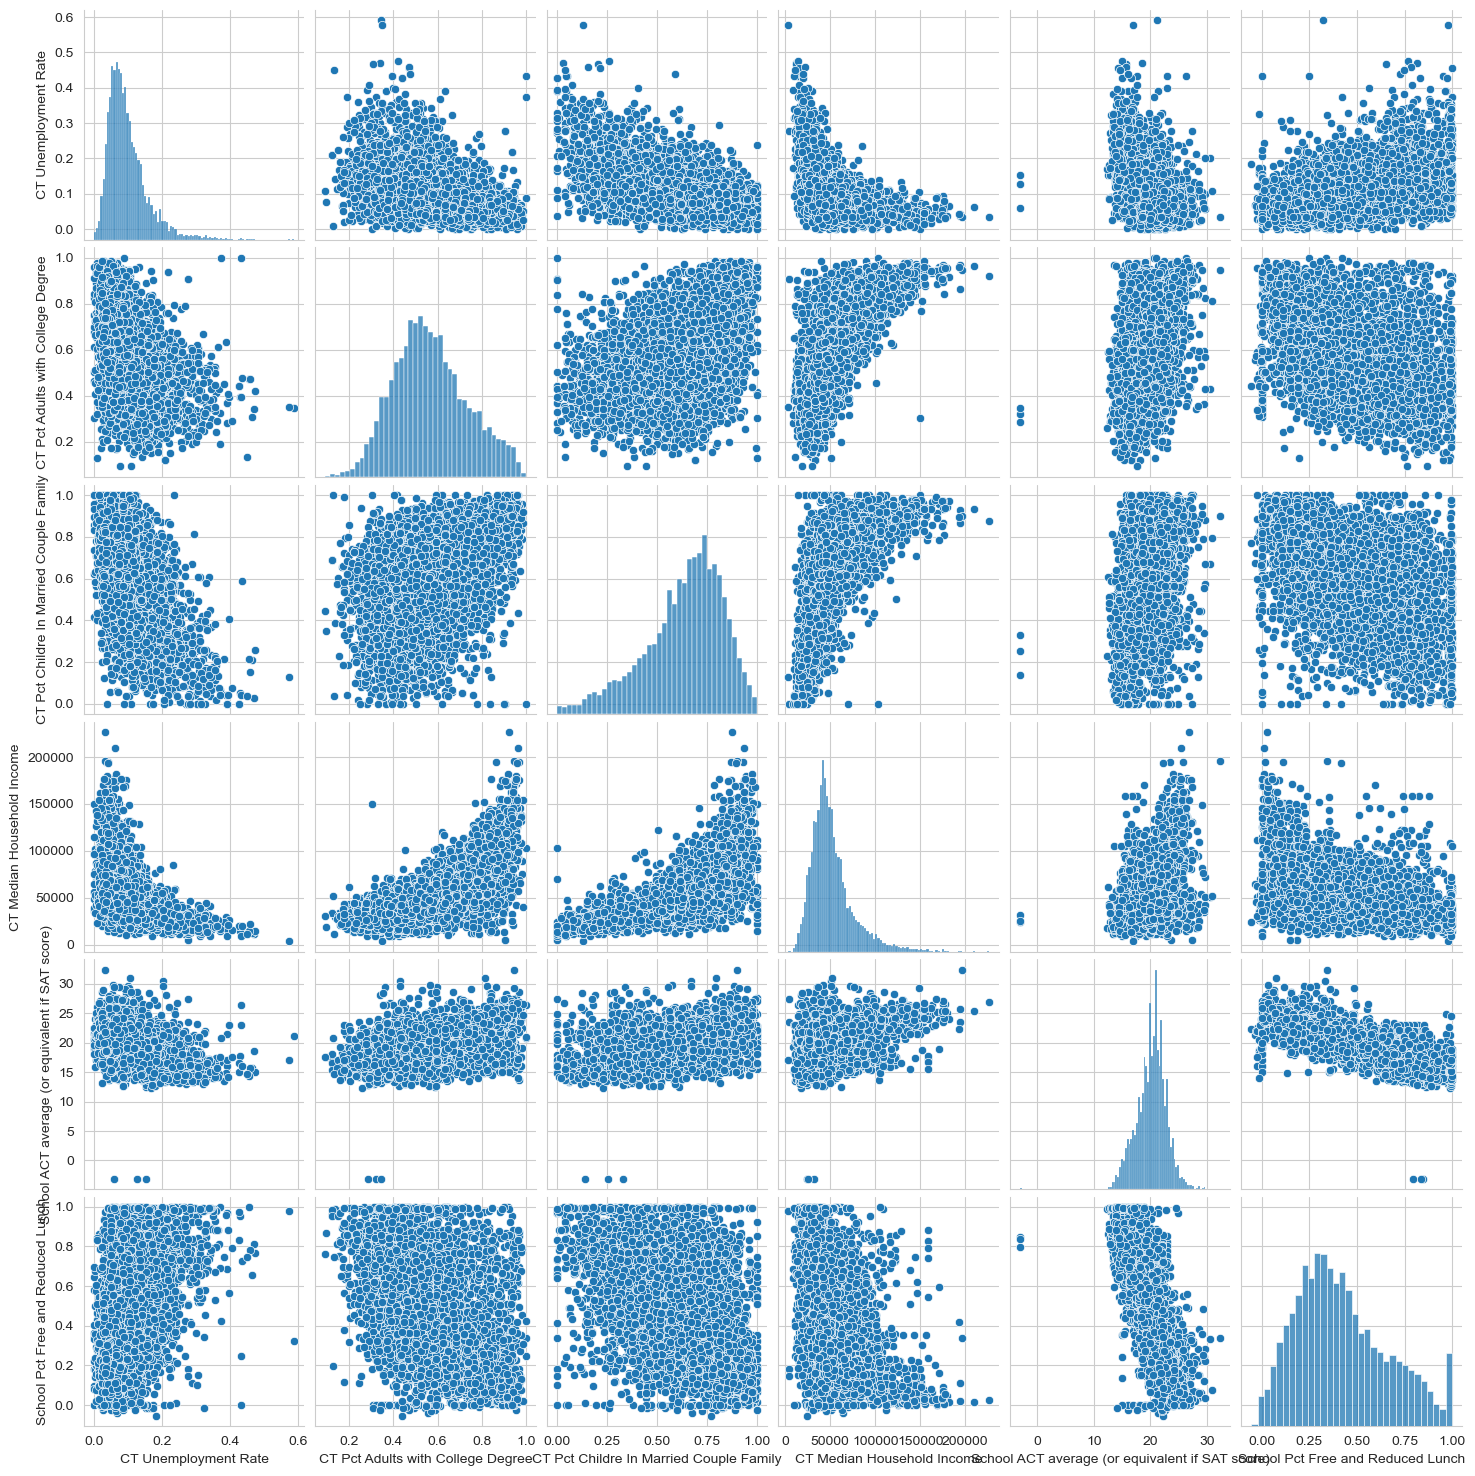

In [21]:
sns.pairplot(
    edgap.drop(columns="NCESSCH School ID")
);
plt.show()

Most of the variables are related to each other. The labels on the bottom row overlap and the income axis is hard to read, so I redraw the plot below with smaller, rotated labels and a regression line on each scatter plot.

Most variables are related to each other, so the socioeconomic measures tend to move together. The labels on the bottom row overlap and the income axis is hard to read, so I redraw the plot below with smaller, rotated labels and add a regression line to each scatter plot.

This version adds a blue regression line to each scatter plot and makes the points smaller and partly transparent so dense areas are easier to see. Median household income is shown in scientific notation so its axis labels fit.

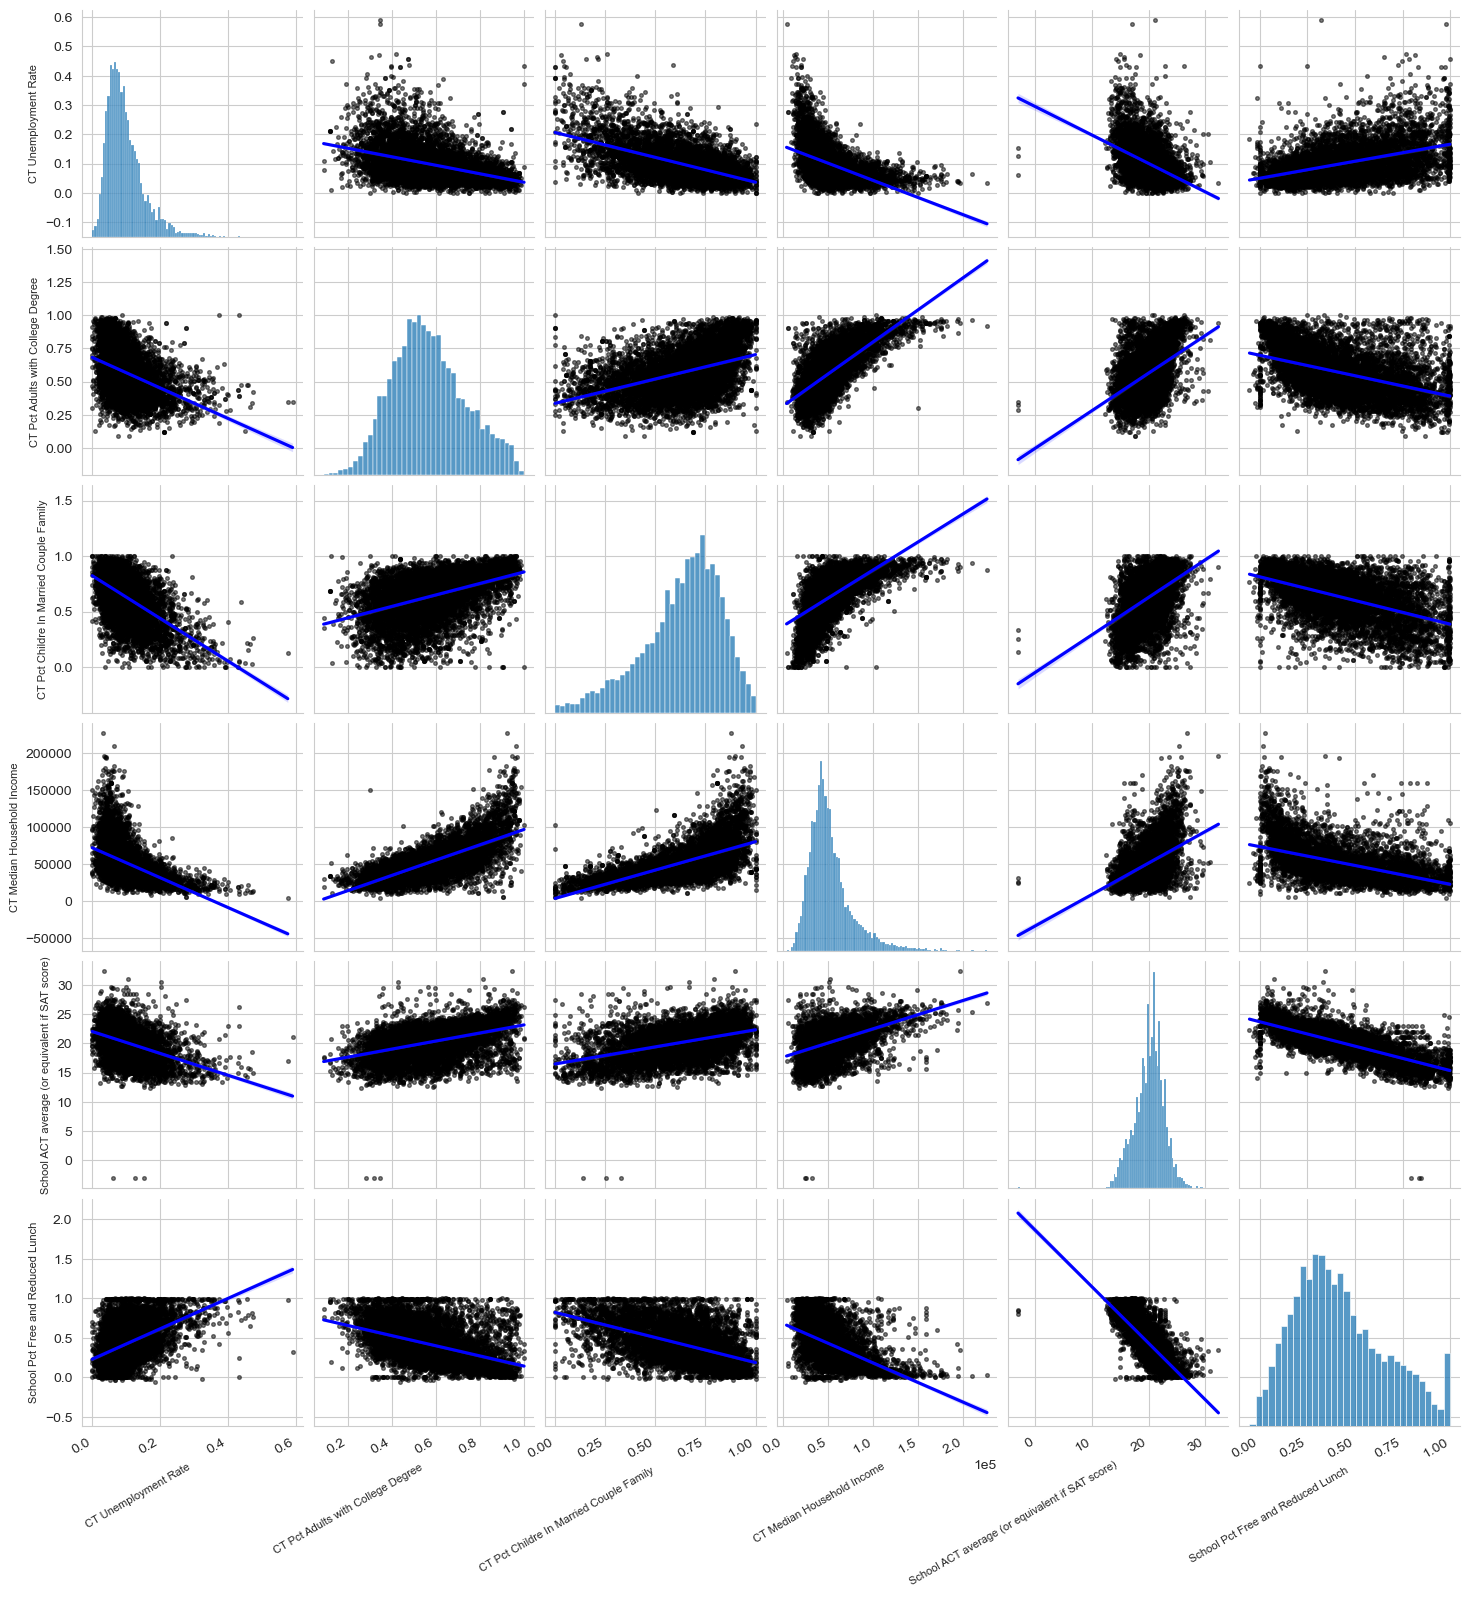

In [25]:
fig = sns.pairplot(
    edgap.drop(columns="NCESSCH School ID"),
    kind="reg",
    plot_kws={
        "line_kws": {"color": "blue"},
        "scatter_kws": {"alpha": 0.5, "color": "k", "s": 7},
    },
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == "CT Median Household Income":
        ax.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
    ax.set_xlabel(ax.get_xlabel(), fontsize=8, rotation=30, ha="right")
    ax.set_ylabel(ax.get_ylabel(), fontsize=8)
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

plt.show()

What the plot shows:

- **Free and reduced lunch has the strongest relationship with ACT scores.** Schools with more students on free or reduced lunch have clearly lower average ACT scores.
- **The census-tract measures are related to ACT too, but more weakly.** ACT scores rise with the percent of adults with a college degree, the percent of children in married-couple families, and median income, and fall as unemployment rises.
- **The predictors are related to each other.** For example, tracts with more college graduates have higher median incomes. Because of this, a model may have trouble separating the effect of each one.
- **Median household income is right-skewed.** Most tracts are below about \$100,000, with a long tail of high-income tracts, and its relationship with the other variables looks curved rather than straight.
- **A few ACT scores are impossible.** A small group of points sits below zero on the ACT axis. ACT scores range from 1 to 36, so these are data errors that I fix in the Quality Control section.

## Data Preparation

I rename the NCES columns I need to short, lowercase names. `NCESSCH` becomes `id` so it matches the EdGap ID column after I rename that one too.

In [28]:
school_information = school_information.rename(
    columns={
        "SCHOOL_YEAR": "year",
        "NCESSCH": "id",
        "LSTATE": "state",
        "LZIP": "zip_code",
        "SCH_TYPE_TEXT": "school_type",
        "LEVEL": "school_level",
        "CHARTER_TEXT": "charter",
    }
)

The columns are renamed. Next I keep only the renamed columns and drop the other 58.

In [30]:
school_information = school_information[
    ["year", "id", "state", "zip_code", "school_type", "school_level", "charter"]
]

I check the result with `head()`.

In [32]:
school_information.head()

,year,id,state,zip_code,school_type,school_level,charter
0,2016-2017,010000200277,AL,35220,Alternative School,High,No
1,2016-2017,010000201667,AL,36067,Alternative School,High,No
2,2016-2017,010000201670,AL,36784,Alternative School,High,No
3,2016-2017,010000201705,AL,36057,Alternative School,High,No
4,2016-2017,010000201706,AL,35206,Alternative School,High,No


`school_information` now has only the seven columns I need. The IDs keep their leading zero (for example, `010000200277`), which shows the file was read correctly.

I also give the EdGap columns short, lowercase, snake_case names. The original column "CT Pct Childre In Married Couple Family" is misspelled in the source file, so I use the misspelled name so that it matches.

In [35]:
edgap = edgap.rename(
    columns={
        "NCESSCH School ID": "id",
        "CT Pct Adults with College Degree": "percent_college",
        "CT Unemployment Rate": "rate_unemployment",
        "CT Pct Childre In Married Couple Family": "percent_married",
        "CT Median Household Income": "median_income",
        "School ACT average (or equivalent if SAT score)": "average_act",
        "School Pct Free and Reduced Lunch": "percent_lunch",
    }
)

I check the new names with `head()`.

In [37]:
edgap.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


All seven EdGap columns now have short names, and the school ID column is called `id`, the same as in `school_information`.

I confirm the column types in `school_information` before merging.

In [40]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102183 entries, 0 to 102182
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   year          102183 non-null  object
 1   id            102181 non-null  object
 2   state         102183 non-null  object
 3   zip_code      102183 non-null  object
 4   school_type   102181 non-null  object
 5   school_level  102179 non-null  object
 6   charter       102179 non-null  object
dtypes: object(7)
memory usage: 5.5+ MB


Every column in `school_information` is stored as text, including `id`. Two rows are missing an `id`, and a few rows are missing `school_type`, `school_level`, or `charter`.

The two data sets store the school ID differently. In EdGap it is a number (`100001600143`), and in the NCES file it is text with a leading zero (`010000200277`). Pandas only merges rows whose IDs are exactly equal, so I convert both to whole numbers first. The two NCES rows without an ID have to be removed before the conversion, because a missing value cannot be stored as a whole number.

In [43]:
school_information = school_information.dropna(subset=["id"])
school_information["id"] = school_information["id"].astype("int64")
edgap["id"] = edgap["id"].astype("int64")

Both `id` columns are now whole numbers, so the same school has the same ID in both data sets.

I merge the two data sets on `id`. A left merge keeps every EdGap school. Schools that are not in the NCES file stay in the data with missing values in the NCES columns.

In [46]:
df = edgap.merge(
    school_information,
    how="left",
    on="id",
)

The merged data set is called `df`. I check how many schools matched below.

In [48]:
df['id'] = df['id'].astype(str)

`id` is now stored as text.

I look at the first rows and the column summary of the merged data.

In [51]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


The NCES columns (`year` through `charter`) are now filled in for these schools, so the merge worked.

In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7986 non-null   object 
 1   rate_unemployment  7972 non-null   float64
 2   percent_college    7973 non-null   float64
 3   percent_married    7961 non-null   float64
 4   median_income      7966 non-null   float64
 5   average_act        7986 non-null   float64
 6   percent_lunch      7986 non-null   float64
 7   year               7898 non-null   object 
 8   state              7898 non-null   object 
 9   zip_code           7898 non-null   object 
 10  school_type        7898 non-null   object 
 11  school_level       7898 non-null   object 
 12  charter            7898 non-null   object 
dtypes: float64(6), object(7)
memory usage: 811.2+ KB


`df` has all 7,986 EdGap schools. 7,898 of them (about 99%) matched a school in the NCES file. The other 88 have missing values in every NCES column, which most likely means their IDs are not in the 2016–2017 directory.

## Quality Control

I check the numeric columns for values that are impossible or unlikely.

In [56]:
df.describe()

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729


Most values are reasonable, with two clear problems:

- **`average_act` has a minimum of −3.07.** ACT scores range from 1 to 36, so a negative average is impossible.
- **`percent_lunch` has a minimum of −0.05.** A percentage cannot be negative.

A few other values are unusual but possible, so I leave them alone: an unemployment rate or married-family share of 0, and a median household income as low as \$3,589.

For a shorter view, I show only the minimum and maximum of each numeric column, rounded to two decimal places.

In [59]:
df.select_dtypes(include=['number']).agg(['min', 'max']).round(2)

,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch
min,0.00,0.09,0.0,3589.0,-3.07,-0.05
max,0.59,1.00,1.0,226181.0,32.36,1.00


This confirms the problems found above. `average_act` goes down to −3.07 and `percent_lunch` goes down to −0.05. Every other column stays within a possible range.

I replace the impossible values with `NaN` (missing) so they are not treated as real data. Any ACT average below 1 and any free-lunch percentage below 0 is set to missing.

In [62]:
df.loc[df["percent_lunch"] < 0, "percent_lunch"] = np.nan
df.loc[df["average_act"] < 1, "average_act"] = np.nan

The impossible values are now marked as missing. I handle them along with the other missing values below.

The ACT is taken by high school students, so I keep only schools that NCES lists as high schools. This also removes the 88 schools that did not match, because their `school_level` is missing.

In [65]:
df = df.loc[df["school_level"] == "High"]

`df` now contains 7,230 high schools.

I check whether any rows are exact duplicates.

In [68]:
df.duplicated().sum()

0

There are no duplicate rows, so no school appears twice.

I count the missing values in each column.

In [71]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,3
percent_lunch,20
year,0
state,0
zip_code,0


After filtering to high schools, the NCES columns have no missing values. The census-tract columns are each missing 11 to 20 values. `average_act` is missing 3 values and `percent_lunch` is missing 20; these are the impossible values I set to missing earlier.

To see where the schools are, I map the number of high schools in each state.

In [74]:
state_counts = df["state"].value_counts()

layout = dict(
    geo={"scope": "usa"},
    coloraxis_colorbar=dict(title="Number of Schools"),
)

choropleth = dict(
    type="choropleth",
    locations=state_counts.index,
    locationmode="USA-states",
    z=state_counts.values,
    coloraxis="coloraxis",
)

state_map = pg.Figure(data=[choropleth], layout=layout)

po.iplot(state_map)

The data covers only 20 states, and they are not equally represented. Texas has the most schools (913), followed by Ohio (654), Illinois (564), and Pennsylvania (543). Wyoming (38) and Delaware (24) have the fewest. Large parts of the country are missing, including California and most other western states, several southern states such as Alabama, Mississippi, and Virginia, and all of New England except Massachusetts. Results from this data may not apply to the whole country.

## Handling Missing Values

`average_act` is the outcome I want to predict, so I do not fill it in. A made-up ACT score would bias the results. I drop the 3 schools with a missing ACT average instead.

In [77]:
df = df.dropna(subset=['average_act'])

Three schools were removed, which leaves 7,227 high schools.

I count the missing values again.

In [80]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,12
percent_college,11
percent_married,20
median_income,16
average_act,0
percent_lunch,20
year,0
state,0
zip_code,0


`average_act` has no missing values now. The only missing values left are in the predictor columns: 11 to 20 each in the census-tract measures and 20 in `percent_lunch`.

I list the variables I plan to use as predictors of ACT scores.

In [83]:
predictor_variables = [
    'rate_unemployment',
    'percent_college',
    'percent_married',
    'median_income',
    'percent_lunch',
    'state',
    'charter'
]

There are seven predictors. Five are numeric (the census-tract measures and `percent_lunch`), and two are categories (`state` and `charter`).

I fill in the missing predictor values with scikit-learn's `IterativeImputer`. It estimates each missing value from the other variables, which works well here because the predictors are correlated with each other. It only works with numbers, so I first make a list of just the numeric predictors.

In [86]:
numerical_predictors = (
    df[predictor_variables].select_dtypes(include="number").columns.to_list()
)

print(numerical_predictors)

['rate_unemployment', 'percent_college', 'percent_married', 'median_income', 'percent_lunch']


The five numeric predictors are selected. `state` and `charter` are left out because they are text.

I create the imputer and fit it on the numeric predictors so it learns how they relate to each other.

In [89]:
imputer = IterativeImputer()
imputer.fit(df.loc[:, numerical_predictors])

IterativeImputer()

The output shows the fitted imputer with its default settings.

I use the fitted imputer to replace the missing values in the numeric predictors.

In [92]:
df.loc[:, numerical_predictors] = imputer.transform(df.loc[:, numerical_predictors])

The missing values in the numeric predictors are now filled in. I confirm this below.

In [94]:
df.isna().sum().to_frame(name='Number of Missing Values')

,Number of Missing Values
id,0
rate_unemployment,0
percent_college,0
percent_married,0
median_income,0
average_act,0
percent_lunch,0
year,0
state,0
zip_code,0


No column has any missing values, so the data is ready for analysis.

## Saving the Clean Data

I save the clean data set as a CSV file so I can use it in later notebooks.

In [97]:
df.to_csv(
    os.path.expanduser("~/Python Projects/education/data/education_clean.csv"),
    encoding="utf-8-sig",
    index=False,
)

`education_clean.csv` is saved with 7,227 high schools and 13 columns, with no missing values.

# Modeling

Now that the data is clean, I build linear regression models to answer the question. I start with one predictor at a time, then use several predictors together, and finally add charter status as my additional predictor. I compare the models using R-squared (the share of the variation in ACT scores the model explains) and the mean absolute error (MAE, how many ACT points the predictions are off by on average).

Disclaimer: AI aided - used AI to help with the syntax for the models and to check my interpretations.

## Regression Line

### Free and reduced lunch and ACT scores

The pair plot showed that free and reduced lunch had the strongest relationship with ACT scores, so I start by plotting it on its own with a regression line.

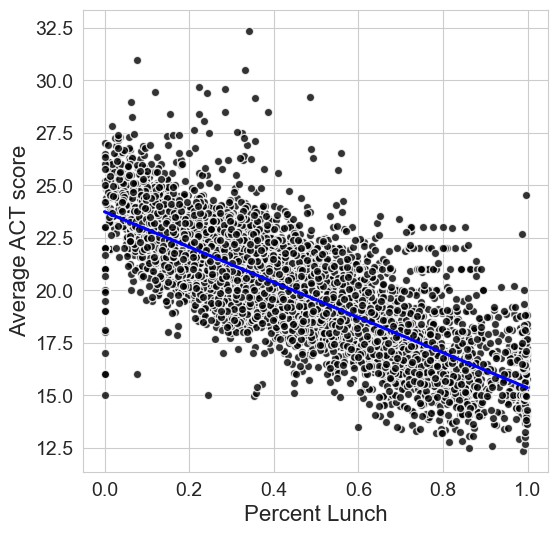

In [103]:
plt.figure(figsize=(6, 6))

sns.regplot(data=df,
            x='percent_lunch',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Percent Lunch', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

There is a clear negative relationship. Schools with almost no students on free or reduced lunch average about 24 on the ACT, while schools where nearly every student qualifies average about 15.5. The points stay fairly close to the line across the whole range. There are vertical stripes at 0 and 1, which are schools that reported 0% or 100% of students on free or reduced lunch.

### Median income and ACT scores

Next I plot median household income against average ACT score.

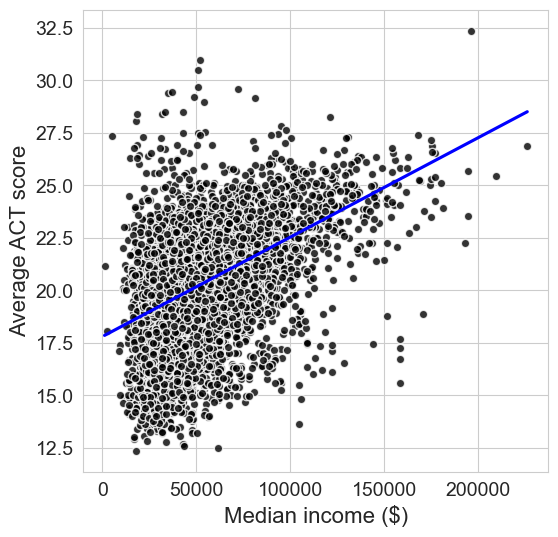

In [106]:
plt.figure(figsize=(6, 6))

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Median income ($)', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

ACT scores go up as median income goes up, but the points are much more spread out than in the free lunch plot. At incomes around \$50,000, ACT averages range from about 13 to 28. At the highest incomes, most points fall below the line, which suggests the relationship might curve and level off instead of being a straight line.

### Simple linear regression with median income

I fit a linear regression model that predicts average ACT score from median income alone.

In [109]:
model_median_income = smf.ols(formula='average_act ~ median_income', data=df).fit()
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:09:13   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8026      0.063    284.794

The coefficient for `median_income` is 4.732e-05, which means that each additional \$10,000 in median income is associated with an ACT average about 0.47 points higher. The p-value is below 0.001, so the relationship is statistically significant. The R-squared is 0.211, so income alone explains about 21% of the variation in ACT scores. The large condition number warning here is because income is measured in dollars (very large numbers), not because of multicollinearity, since there is only one predictor.

I calculate the R-squared, root mean squared error (RMSE), and mean absolute error (MAE) for this model.

In [112]:
model_median_income.rsquared
y_hat = model_median_income.predict()
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)
mean_absolute_error(df['average_act'], y_hat)

print("R-squared:", round(model_median_income.rsquared, 3))
print("RMSE:", np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3))
print("MAE:", round(mean_absolute_error(df['average_act'], y_hat), 3))

R-squared: 0.211
RMSE: 2.228
MAE: 1.713


The R-squared is 0.211, the RMSE is 2.228, and the MAE is 1.713. This means the model's predictions are off by about 1.7 ACT points on average.

To check whether a straight line is a good fit, I plot the residuals (actual minus predicted ACT score) against the predicted values. If the model fits well, the residuals should be spread evenly around 0 with no pattern.

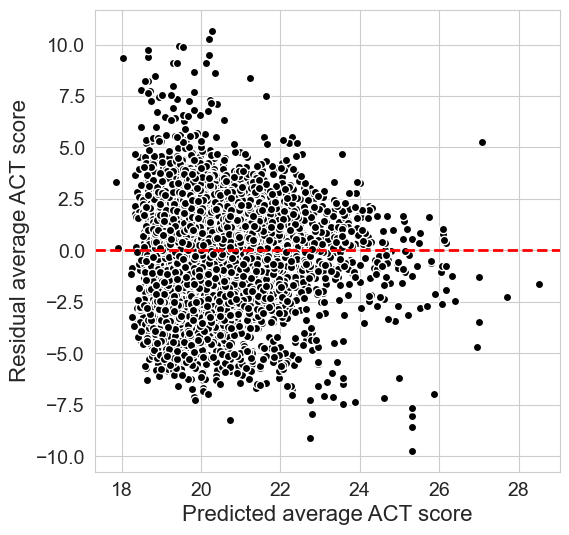

In [115]:
plt.figure(figsize=(6, 6))

plt.plot(y_hat, model_median_income.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

The residuals are not spread evenly. Most predictions fall between 18 and 22, and for the higher predicted values the residuals are mostly below 0, meaning the model predicts scores that are too high for the highest-income schools. This pattern suggests the relationship is curved, so I try a quadratic model next.

### Quadratic model with median income

I plot the straight regression line (blue) and a quadratic curve (orange) on the same graph to compare them.

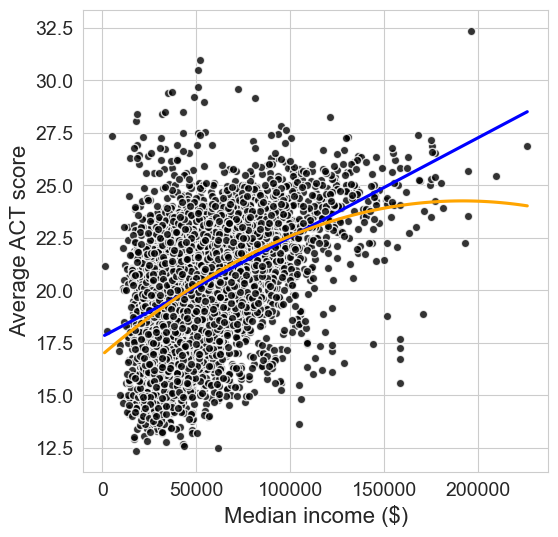

In [118]:
plt.figure(figsize=(6, 6))

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            order=2,
            color='orange',
            ci=False,
            scatter=False)

# Add axis labels
plt.xlabel('Median income ($)', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize=14)

plt.show()

The two lines are almost the same for incomes up to about \$100,000. Above that, the quadratic curve bends down and levels off around an ACT score of 24, which follows the high-income schools better than the straight line does.

I fit the quadratic model by adding a squared income term.

In [121]:
model_median_income2 = smf.ols(
    formula='average_act ~ median_income + I(median_income**2)',
    data=df).fit()

print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:09:15   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

Both income terms are significant. The squared term is negative (-1.99e-10), which means the effect of income gets smaller as income gets higher. This matches the curve in the plot. The R-squared went up only slightly, from 0.211 to 0.219.

I look at the p-values for each term in the quadratic model.

In [124]:
model_median_income2.pvalues

Intercept                0.000000e+00
median_income            2.631899e-99
I(median_income ** 2)    1.395848e-17
dtype: float64

The p-values are 2.6e-99 for `median_income` and 1.4e-17 for the squared term, so both are far below 0.05.

To test whether the quadratic model is significantly better than the linear model, I use an ANOVA F-test to compare the two models.

In [127]:
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.012794,0.0,NaN,NaN,NaN
1,7224.0,35505.105960,1.0,359.906834,73.227974,1.395848e-17


The F statistic is 73.2 and the p-value is 1.4e-17, so adding the squared term significantly improves the model.

I calculate the mean absolute error for the quadratic model.

In [130]:
mean_absolute_error(df['average_act'], model_median_income2.predict())

1.6972389257904303

The quadratic model has an MAE of 1.697.

For comparison, I calculate the MAE for the linear model again.

In [133]:
mean_absolute_error(df['average_act'], model_median_income.predict())

1.7129386980688623

The linear model has an MAE of 1.713, so the quadratic model only improves predictions by about 0.016 ACT points. Even though the improvement is statistically significant, it is very small in practice. Income alone explains only about 22% of the variation in ACT scores, so I add more predictors next.

## Multiple Linear Regression

I fit a model that uses all five socioeconomic predictors together: unemployment rate, percent college, percent married, median income, and percent on free or reduced lunch.

In [137]:
model = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch',
    data=df).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     2438.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:09:15   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.667e+04
Df Residuals:                    7221   BIC:                         2.671e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6972      0.13

The R-squared jumps to 0.628, so the five predictors together explain about 63% of the variation in ACT scores, compared to 21% for income alone.

- **`percent_lunch` has the biggest effect.** Its coefficient is -7.60, so going from 0% to 100% of students on free or reduced lunch is associated with an ACT average about 7.6 points lower.
- **`percent_college` (1.74) and `rate_unemployment` (-2.27) are also significant**, with p-values below 0.001.
- **`percent_married` (p = 0.577) and `median_income` (p = 0.920) are not significant** once the other predictors are in the model. Income was significant on its own, but it is so closely related to percent college and percent lunch that it does not add any new information. The large condition number (1.34e+06) is another sign that the predictors overlap.

I make a residual plot for the multiple regression model.

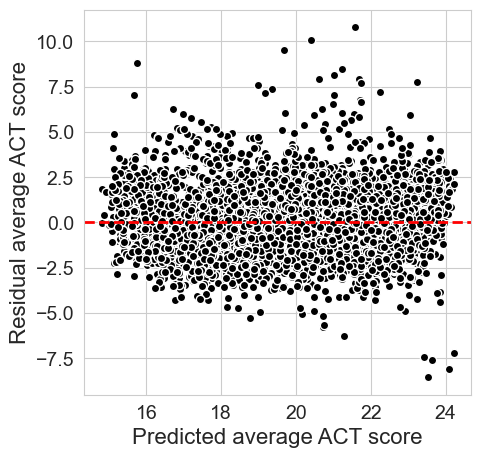

In [140]:
y_hat = model.predict()
plt.figure(figsize=(5, 5))

plt.plot(y_hat, model.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

The residuals are much more evenly spread around 0 than in the income-only model, and there is no clear curve. Most residuals are between -5 and 5. There are a few schools with residuals up to about 10, which scored much higher than the model predicted, and a small group near -7.5 at high predicted values that scored much lower than expected.

I calculate the MAE for the multiple regression model.

In [143]:
mean_absolute_error(df['average_act'],model.predict())
print("MAE:", round(mean_absolute_error(df['average_act'], y_hat), 3))

MAE: 1.145


The MAE is 1.145, which is about 33% smaller than the 1.713 from the income-only model.

## Reduced Model

Since `percent_married` and `median_income` were not significant, I fit a reduced model without them to see if the simpler model works just as well.

In [147]:
model_reduced = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_lunch',
    data=df).fit()
print(model_reduced.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:09:15   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6400      0.10

The reduced model has the same R-squared as the full model (0.628). All three predictors are significant with p-values below 0.001, and their coefficients are almost the same as before: -7.59 for percent lunch, 1.71 for percent college, and -2.17 for unemployment. The condition number dropped from 1.34e+06 to 25.9, so the multicollinearity warning is gone.

I make a residual plot for the reduced model.

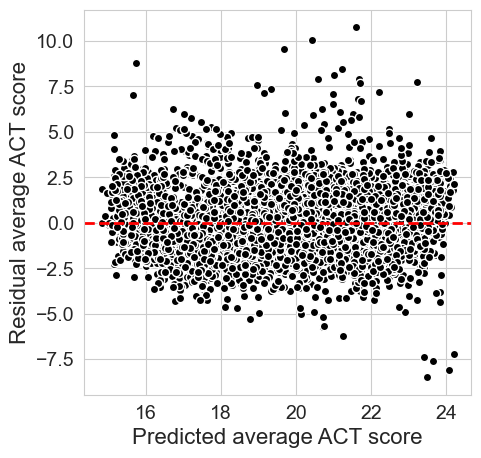

In [150]:
y_hat = model_reduced.predict()

plt.figure(figsize=(5, 5))

plt.plot(y_hat, model_reduced.resid, 'ko', mec='w')
plt.axhline(0, color='r', linestyle='dashed', lw=2)

plt.xlabel('Predicted average ACT score', fontsize=16)
plt.ylabel('Residual average ACT score', fontsize=16)

plt.tick_params(labelsize=14)

plt.show()

The residual plot looks almost identical to the full model's. The residuals are spread evenly around 0 with no clear pattern.

I calculate the MAE for the reduced model.

In [153]:
mean_absolute_error(df['average_act'],model_reduced.predict())
print("MAE:", round(mean_absolute_error(df['average_act'], y_hat), 3))

MAE: 1.145


The MAE is 1.145, the same as the full model when rounded.

I put the MAE and R-squared for the full and reduced models side by side in a table.

In [156]:
mae_full = mean_absolute_error(df['average_act'], model.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_full = model.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_full, mae_reduced],
              'R-squared': [r2_full, r2_reduced]},
             index=['full model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
full model,1.1453,0.6280
reduced model,1.1455,0.6279


The two models are almost exactly the same. The full model has an MAE of 1.1453 and an R-squared of 0.6280, and the reduced model has an MAE of 1.1455 and an R-squared of 0.6279.

I use an ANOVA F-test to check whether the two extra predictors in the full model significantly improve it.

In [159]:
anova_lm(model_reduced,model)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7221.0,16915.612457,2.0,1.006711,0.214874,0.806648


The p-value is 0.81, which is far above 0.05. This means that removing `percent_married` and `median_income` does not make the model significantly worse. Since the reduced model fits just as well with fewer predictors, I prefer the reduced model.

## Scaling

The coefficients in the reduced model are hard to compare because the predictors are on different scales. For example, a 1-unit change in unemployment rate (0 to 100%) is a much bigger change than is realistic. To compare the predictors fairly, I create derived variables by standardizing each predictor so it has a mean of 0 and a standard deviation of 1.

In [163]:
predictor_variables = ['rate_unemployment', 'percent_college', 'percent_lunch']
scaled_columns = [var + '_normalized' for var in predictor_variables]

scaler = StandardScaler().fit(df[predictor_variables])
df[scaled_columns] = scaler.transform(df[predictor_variables])

print("Predictor variables:", predictor_variables)
print("Scaled columns:", scaled_columns)
print("\nScaler means:", scaler.mean_.round(4))
print("Scaler standard deviations:", scaler.scale_.round(4))
print("\nCheck (scaled columns should have mean ≈ 0, std ≈ 1):")
print(df[scaled_columns].agg(['mean', 'std']).round(4))

Predictor variables: ['rate_unemployment', 'percent_college', 'percent_lunch']
Scaled columns: ['rate_unemployment_normalized', 'percent_college_normalized', 'percent_lunch_normalized']

Scaler means: [0.0965 0.573  0.4105]
Scaler standard deviations: [0.0566 0.1649 0.2342]

Check (scaled columns should have mean ≈ 0, std ≈ 1):
      rate_unemployment_normalized  percent_college_normalized  \
mean                        0.0000                      0.0000   
std                         1.0001                      1.0001   

      percent_lunch_normalized  
mean                    0.0000  
std                     1.0001  


The three new columns end with `_normalized`. The original means were 0.097 for unemployment, 0.573 for percent college, and 0.411 for percent lunch. After scaling, every new column has a mean of 0 and a standard deviation of 1.

I double check the mean and standard deviation of the scaled columns.

In [166]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_lunch_normalized
mean,0.0,0.0,0.0
std,1.0,1.0,1.0


All three scaled columns have a mean of 0 and a standard deviation of 1, so the scaling worked.

I fit the reduced model again using the standardized predictors.

In [169]:
model_normalized = smf.ols(
    formula='average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_lunch_normalized',
    data=df).fit()

print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.628
Model:                            OLS   Adj. R-squared:                  0.628
Method:                 Least Squares   F-statistic:                     4063.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:09:16   Log-Likelihood:                -13328.
No. Observations:                7227   AIC:                         2.666e+04
Df Residuals:                    7223   BIC:                         2.669e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

Now the coefficients show the change in ACT score for a one standard deviation change in each predictor. Percent lunch has by far the largest effect at -1.78 points. Percent college is next at 0.28 points, and unemployment has the smallest effect at -0.12 points. The effect of free and reduced lunch is about 6 times bigger than percent college and about 14 times bigger than unemployment. The intercept of 20.30 is the predicted ACT score for a school with average values for all three predictors.

I compare the normalized model with the reduced model.

In [172]:
mae_normalized = mean_absolute_error(df['average_act'], model_normalized.predict())
mae_reduced = mean_absolute_error(df['average_act'], model_reduced.predict())

r2_normalized = model_normalized.rsquared
r2_reduced = model_reduced.rsquared

pd.DataFrame({'Mean Absolute Error': [mae_normalized, mae_reduced],
              'R-squared': [r2_normalized, r2_reduced]},
             index=['normalized model', 'reduced model']).round(4)

,Mean Absolute Error,R-squared
normalized model,1.1455,0.6279
reduced model,1.1455,0.6279


The MAE and R-squared are exactly the same. Scaling only changes the units of the predictors, so the predictions do not change. The only thing that changes is that the coefficients can now be compared to each other.

## Additional Predictor: Charter Schools

Charter schools are public schools that run independently of the local school district, and they often have different teaching approaches, schedules, and admission processes. Some people argue that charter schools do a better job than regular public schools, while others argue that they mostly serve students who were already doing well. I want to see whether charter schools have different average ACT scores after taking poverty and the other socioeconomic factors into account.

First I look at how many schools are charter schools and their average ACT score.

In [175]:
df.groupby("charter")["average_act"].agg(["count", "mean"]).round(2)

,count,mean
charter,,
No,6858,20.36
Not applicable,199,19.25
Yes,170,19.02


Only 170 of the 7,227 high schools are charter schools. Charter schools have a lower average ACT score (19.02) than non-charter schools (20.36). There is also a third group, "Not applicable," with 199 schools. Almost all of these (198) are in Kentucky.

Charter schools also have more students on free or reduced lunch on average (54% compared to 41% for non-charter schools), so part of the lower ACT average could be explained by poverty instead of by being a charter school. The regression model below checks this.

I add charter status to the reduced model. `C(charter)` tells statsmodels to treat charter status as a category instead of a number.

In [178]:
model_charter = smf.ols(
    formula="average_act ~ rate_unemployment + percent_college + percent_lunch + C(charter)",
    data=df).fit()

print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.630
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     2459.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:09:16   Log-Likelihood:                -13308.
No. Observations:                7227   AIC:                         2.663e+04
Df Residuals:                    7221   BIC:                         2.667e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

Non-charter schools ("No") are the baseline group, so the charter coefficients are compared to non-charter schools with the same socioeconomic values.

- **Charter schools (`Yes`):** The coefficient is -0.18 with a p-value of 0.128, so it is not significant. The raw gap of about 1.3 ACT points shrinks to about 0.2 points once poverty, college education, and unemployment are taken into account, and that remaining difference could be due to chance.
- The other coefficients barely changed, and the R-squared went from 0.628 to 0.630.

I use an ANOVA F-test to check whether adding charter status significantly improves the reduced model.

In [181]:
anova_lm(model_reduced, model_charter)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7223.0,16916.619167,0.0,NaN,NaN,NaN
1,7221.0,16821.669533,2.0,94.949634,20.379407,1.493554e-09


The F statistic is 20.4 and the p-value is 1.5e-09, so adding the charter variable significantly improves the model. However, based on the coefficients above, this improvement comes from the Kentucky ("Not applicable") group and not from the charter schools themselves.

I compare the MAE and R-squared of the reduced model and the charter model.

In [184]:
mae_charter = mean_absolute_error(df["average_act"], model_charter.predict())
r2_charter = model_charter.rsquared

pd.DataFrame({"Mean Absolute Error": [mae_reduced, mae_charter],
              "R-squared": [r2_reduced, r2_charter]},
             index=["reduced model", "charter model"]).round(4)

,Mean Absolute Error,R-squared
reduced model,1.1455,0.6279
charter model,1.1404,0.6300


The MAE only drops from 1.1455 to 1.1404 and the R-squared goes from 0.6279 to 0.6300. Adding the charter variable is a statistically significant improvement, but it makes almost no practical difference to the predictions.

## Conclusion

Socioeconomic factors do predict a school's average ACT score. My best model was the reduced model, which uses the percent of students on free or reduced-price lunch, the percent of adults in the area with a college degree, and the unemployment rate. Together these three predictors explain about 63% of the variation in average ACT scores, and the model's predictions are off by about 1.15 ACT points on average. The full model with all five socioeconomic predictors did not do any better (ANOVA p-value of 0.81), so the simpler model is the better choice.

The most important predictor by far was the percent of students on free or reduced-price lunch. After standardizing the predictors, its effect (-1.78 points per standard deviation) was about 6 times bigger than percent college and about 14 times bigger than unemployment. This makes sense because free lunch measures the poverty of the students actually attending the school, while the other measures describe the neighborhood around the school. Median household income was significant on its own and had a curved relationship with ACT scores, but it did not add anything once the other predictors were included.

For my additional predictor, I found that charter schools have lower raw ACT averages than non-charter schools (19.02 compared to 20.36), but they also serve more students on free or reduced lunch. After controlling for the socioeconomic factors, the difference for charter schools was small (-0.18 points) and not significant (p = 0.128). The charter variable did significantly improve the model, but only because of the "Not applicable" group, which is almost entirely Kentucky schools. This suggests that state differences, such as testing rules, may matter more than charter status.